# E1 · Блага и обязанности

Сравниваем одни и те же входы как блага и как обязанности.
Работаем с небольшими задачами, точный ответ ищем полным перебором.
Проверяем EF1 и SD-EF1, сравниваем точный ориентир с простой эвристикой
и, по желанию, с моделью.

Выберите ядро из этой папки: **Select Kernel → Python Environments →
.venv/bin/python** (Python 3.10+). Затем выполняйте ячейки сверху вниз или
нажмите **Run All / Выполнить всё**. Первая ячейка устанавливает зависимости;
при первой установке нужен интернет. Открывайте ноутбук из папки проекта.
После изменения Python-файлов перезапустите ядро.

[README](README.md) · [Определения метрик](README.md#метрики)

In [1]:
%pip install -e "."

Looking in links: /tmp/e1-notebook-wheelhouse
Obtaining file:///home/jone/delezhiiii


  Installing build dependencies ... -

 \

 done


  Checking if build backend supports build_editable ... done


  Getting requirements to build editable ... -

... (2 outputs left out)

 done


  Building editable for chores-e1 (pyproject.toml) ... -

 done
  Created wheel for chores-e1: filename=chores_e1-0.1.0-0.editable-py3-none-any.whl size=2828 sha256=1e509cb69aab42a2387b1ff76210329f85b738e5d42b69d6060579ca41653157
  Stored in directory: /tmp/pip-ephem-wheel-cache-qwrbw9f2/wheels/9c/55/ec/3ec35cf3ec292c060b97a000ed0b91a815b96a0d3f09e56233
Successfully built chores-e1


Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
from IPython.display import display

from chores_e1 import (
    ExperimentConfig, ModelConfig, Setting,
    generate_instances, make_prompt, run_experiment,
    summary_table, plot_inputs, plot_results,
)

## 1. Настройки

Начнём с 3 участников и 6 предметов: всего 729 распределений.
Можно попробовать `Setting(3, 4)`, `Setting(3, 5)` или `Setting(4, 6)`.
Все остальные настройки для обычной работы находятся в следующей ячейке.

`n_base=5` задаёт быстрый пробный запуск; для исследования увеличьте,
например до 20. Каждая матрица используется и для благ, и для обязанностей.
Группы: «Статья», случайные веса 1–10 и двухзначные оценки r=2,5,10.

По умолчанию модели выключены. Чтобы включить сравнение, задайте
`RUN_MODELS=True` и точный ID в `ModelConfig`. Нужны Codex CLI
и предварительно выполненный `codex login` в среде ядра.
Модель вызывается для всей выбранной выборки; для пробы сократите
`n_base` до 1 и `groups` до `("paper",)`.

In [3]:
RUN_MODELS = False

config = ExperimentConfig(
    settings=(Setting(3, 6),),
    n_base=5,
    seed=20261109,
    groups=("paper", "uniform", "r=2", "r=5", "r=10"),
    repeats=1,
    models=(ModelConfig(label="Codex", model=None),) if RUN_MODELS else (),
)

## 2. Пример входа и задачи

Строки оценок нормируются до 100. Для благ большее число означает большую
полезность, для обязанностей — большую стоимость. Ниже — пример входа
и текст, который получит модель.

Распредели неделимые обязанности. Чем больше оценка набора, тем он обременительнее.
Назначь каждую позицию ровно одному участнику. Пустые наборы разрешены.
В таблице исходные веса. Оценка набора S для участника i равна 100 × (сумма весов позиций S в строке i) / (сумма всех весов в строке i).

Участник | G1 | G2 | G3 | G4 | G5 | G6
A1 | 10 | 71 | 133 | 52 | 29 | 110
A2 | 8 | 39 | 78 | 44 | 19 | 67
A3 | 10 | 62 | 116 | 63 | 13 | 97

Обозначим через X_i набор участника i. Для каждой пары разных участников i и j считай обе оценки от лица i. Удали из X_i самую затратную для i работу, если X_i непуст. Остаток зависти равен max(0, оценка X_i после удаления одной работы − оценка X_j). Если удалять нечего, используй исходный набор. Если все остатки равны нулю, делёж удовлетворяет EF1. Сначала минимизируй максимальный остаток зависти. При равном остатке минимизируй суммарные затраты на назначенные работы.

Верни один JSON без пояснений и без Markdown по схеме {"status": "allocation", "bundles": 

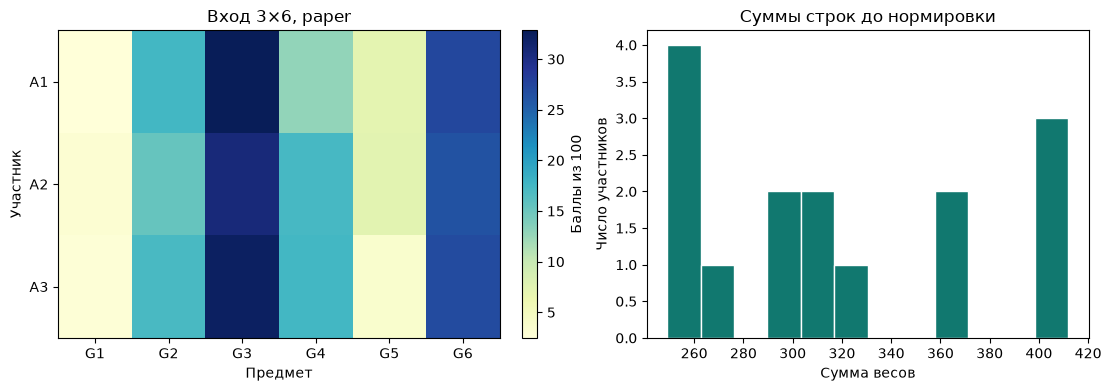

In [4]:
input_figure = plot_inputs(config)
sample = generate_instances(config)[0]
print(make_prompt(sample.weights, "chores", row_total=config.row_total))

## 3. Запуск

Полный перебор находит минимальное нарушение EF1, затем лучший SW/C.
Эвристика благ — round robin, обязанностей — передача работы участнику
с минимальной нормированной стоимостью; гарантия EF1 у второй отсутствует.

Результаты сохраняются в `runs/`. При случайном выборе слишком большого
размера (больше 10 000 распределений) ориентир пропускается:
уменьшите число участников или предметов и повторите запуск.

In [5]:
result = run_experiment(config)
print(f"Результаты: {result.directory.resolve()}")
skipped = (result.references["status"] == "skipped").sum()
if skipped:
    print(f"Пропущено точных ориентиров: {skipped}. Уменьшите размер задачи.")

Результаты: /home/jone/delezhiiii/runs/e1_20261112T172818_4ecba6e3


## 4. Результаты

**EF1** проверяет зависть после удаления одного чужого блага или одной
собственной обязанности. **SD-EF1** дополнительно сравнивает числа предметов
на каждом положительном пороге оценок. Ничьи и нулевые веса учитываются.

В таблице: доли успехов `ef1` и `sd_ef1`, остаток зависти `d`,
суммарная полезность благ или стоимость обязанностей `total`.
Ошибка формата считается неуспехом; её `d` и `total` не определяются.
Повторы усредняются внутри экземпляра, затем между экземплярами.
Интервалы на графиках — 95%-й бутстрэп по базовым матрицам.
При пяти матрицах это предварительные результаты.

Точный ориентир оптимизирует обычную EF1 и SW/C, а не SD-EF1.
Алгоритмические результаты без вызовов моделей не оценивают качество LLM.

In [6]:
table = summary_table(result.rows)
display(table[["ef1", "sd_ef1", "d", "total", "n_instances"]].round(4))
table.to_csv(result.directory / "summary.csv")

ef1  sd_ef1       d     total  \
setting method          kind   group                                    
3×6     Точный ориентир goods  paper    1.0     0.2  0.0000  108.8496   
        Эвристика       goods  paper    1.0     1.0  0.0000  100.7405   
        Точный ориентир chores paper    1.0     0.2  0.0000   91.3453   
        Эвристика       chores paper    0.2     0.0  0.1485   90.6537   
        Точный ориентир goods  uniform  1.0     0.4  0.0000  149.2201   
        Эвристика       goods  uniform  1.0     1.0  0.0000  144.2987   
        Точный ориентир chores uniform  1.0     0.4  0.0000   58.3100   
        Эвристика       chores uniform  0.6     0.0  0.0164   56.4970   
        Точный ориентир goods  r=2      1.0     0.4  0.0000  122.3384   
        Эвристика       goods  r=2      1.0     1.0  0.0000  115.8384   
        Точный ориентир chores r=2      1.0     0.4  0.0000   76.7576   
        Эвристика       chores r=2      0.6     0.2  0.0848   76.2980   
        Точный ориентир goods  r=5      1.0     0.4  0.0000  148.9022   
        Эвристика       goods  r=5      1.0     1.0  0.0000  134.3568   
        Точный ориентир chores r=5      1.0     0.4  0.0000   52.7473   
        Эвристика       chores r=5      0.6     0.2  0.0410   52.2899   
        Точный ориентир goods  r=10     1.0     0.4  0.0000  162.9469   
        Эвристика       goods  r=10     1.0     1.0  0.0000  144.0183   
        Точный ориентир chores r=10     1.0     0.4  0.0000   41.1574   
        Эвристика       chores r=10     0.6     0.2  0.0221   40.8461   

                                        n_instances  
setting method          kind   group                 
3×6     Точный ориентир goods  paper              5  
        Эвристика       goods  paper              5  
        Точный ориентир chores paper              5  
        Эвристика       chores paper              5  
        Точный ориентир goods  uniform            5  
        Эвристика       goods  uniform            5  
        Точный ориентир chores uniform            5  
        Эвристика       chores uniform            5  
        Точный ориентир goods  r=2                5  
        Эвристика       goods  r=2                5  
        Точный ориентир chores r=2                5  
        Эвристика       chores r=2                5  
        Точный ориентир goods  r=5                5  
        Эвристика       goods  r=5                5  
        Точный ориентир chores r=5                5  
        Эвристика       chores r=5                5  
        Точный ориентир goods  r=10               5  
        Эвристика       goods  r=10               5  
        Точный ориентир chores r=10               5  
        Эвристика       chores r=10               5

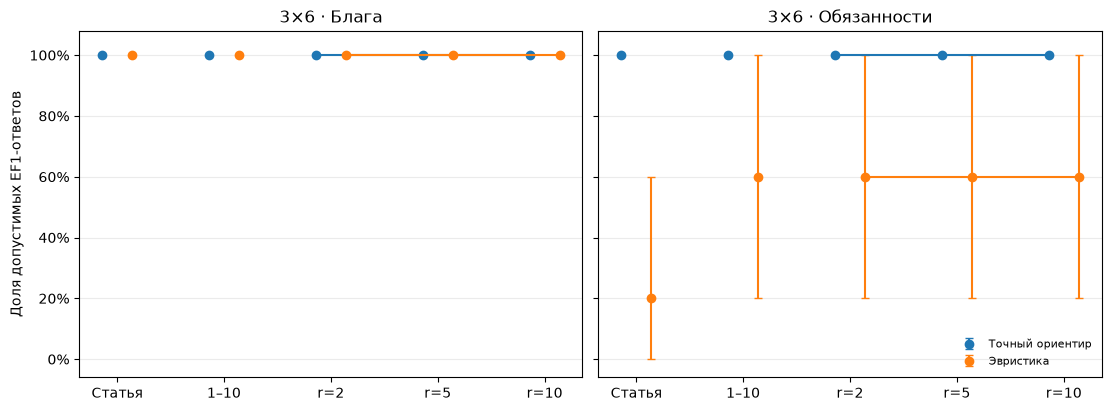

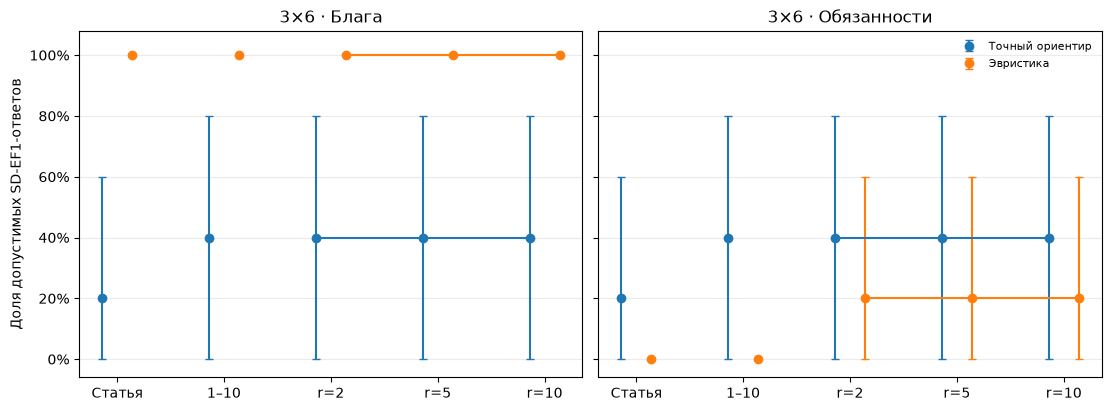

In [7]:
figures = plot_results(result, metrics=("ef1", "sd_ef1"))